# Clustering Before and After PCA
**Mini Project — Group 6**

**Goal:** See how PCA affects K-Means clustering.

**Dataset:** Wine (from sklearn): 178 wines, 13 chemical features, 3 grape types.

PCA turns many features into a few new ones (components) that keep much of the variance.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target   # true grape type, used only to check the result
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 1. Preprocessing

In [ ]:
print("Missing values:", df.isna().sum().sum())

X = StandardScaler().fit_transform(df)

Missing values: 0


No missing values. We scale the data because the features have very different ranges.

## 2. K-Means Before PCA (13 features)

In [ ]:
km_before = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_before = km_before.fit_predict(X)

sil_before = silhouette_score(X, labels_before)
ari_before = adjusted_rand_score(y, labels_before)
print("Silhouette:", round(sil_before, 3))
print("ARI:", round(ari_before, 3))

Silhouette: 0.285
ARI: 0.897


* **Silhouette:** how well the clusters are separated (higher is better).
* **ARI:** how close the clusters are to the real grape types (1 = perfect).

## 3. Apply PCA (2 components)

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

kept = pca.explained_variance_ratio_.sum()
print("Information kept:", round(kept * 100, 1), "%")

Information kept: 55.4 %


2 components keep **55.4%** of the information (we lose 44.6%).

## 4. K-Means After PCA

In [ ]:
km_after = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_after = km_after.fit_predict(X_pca)

sil_after = silhouette_score(X_pca, labels_after)
ari_after = adjusted_rand_score(y, labels_after)
print("Silhouette:", round(sil_after, 3))
print("ARI:", round(ari_after, 3))

Silhouette: 0.561
ARI: 0.895


## 5. Visualization

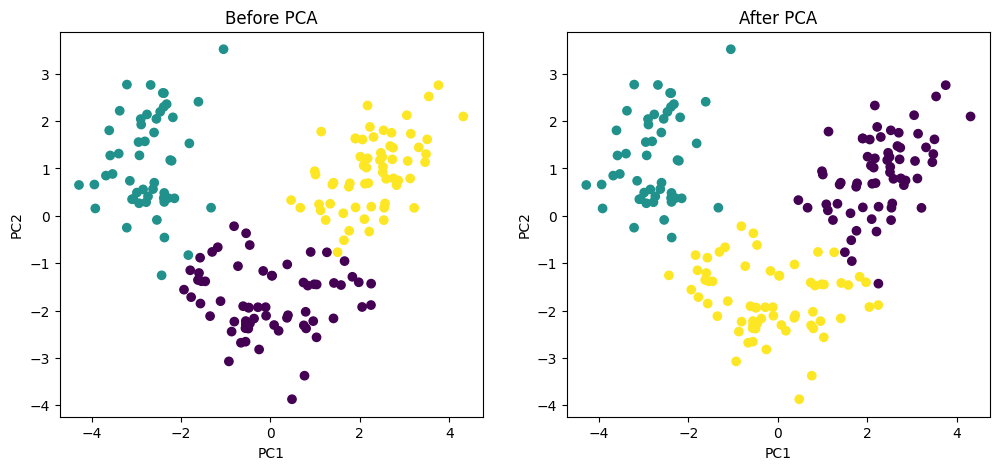

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_before, cmap="viridis")
ax[0].set_title("Before PCA")

ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_after, cmap="viridis")
ax[1].set_title("After PCA")

for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.show()

The colours can differ between the two plots (cluster numbers are random); what matters is that the groups are the same.

## 6. Comparison

In [ ]:
pd.DataFrame({"Silhouette": [sil_before, sil_after],
              "ARI": [ari_before, ari_after]},
             index=["Before PCA", "After PCA"]).round(3)

,Silhouette,ARI
Before PCA,0.285,0.897
After PCA,0.561,0.895


## 7. Analysis

**How did PCA affect the results?**
Almost no change. ARI is 0.897 before and 0.895 after: K-Means found the same groups.

**Did visualization become clearer?**
Yes. We can't plot 13 features, but with 2 components the 3 groups are clear.

**Did we lose information?**
Yes, about 44.6%, but it did not hurt the clustering. The silhouette went up (0.28 → 0.56) partly because it is measured in 2D only.

**Which approach is better?**
After PCA: same quality, only 2 features instead of 13, and easy to visualize.

## 8. Final Summary
* Scaling was needed before K-Means and PCA.
* 2 components kept 55.4% of the information.
* K-Means gave almost the same clusters before and after PCA.
* PCA made the data simpler and easy to visualize without hurting the result.

## 9. Bonus

### 9.1 Different number of components

In [ ]:
for n in [1, 2, 3, 5, 13]:
    Xn = PCA(n_components=n).fit_transform(X)
    labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Xn)
    print(n, "components -> ARI:", round(adjusted_rand_score(y, labels), 3))

1 components -> ARI: 0.505
2 components -> ARI: 0.895
3 components -> ARI: 0.88
5 components -> ARI: 0.897
13 components -> ARI: 0.897


1 component loses too much (ARI 0.505). From 2 components on the result is almost the same, so 2 is enough.

### 9.2 DBSCAN before and after PCA

In [ ]:
from sklearn.cluster import DBSCAN

db_before = DBSCAN(eps=2.4, min_samples=5).fit_predict(X)
db_after = DBSCAN(eps=0.65, min_samples=8).fit_predict(X_pca)

print("DBSCAN before PCA -> ARI:", round(adjusted_rand_score(y, db_before), 3))
print("DBSCAN after PCA  -> ARI:", round(adjusted_rand_score(y, db_after), 3))

DBSCAN before PCA -> ARI: 0.421
DBSCAN after PCA  -> ARI: 0.559


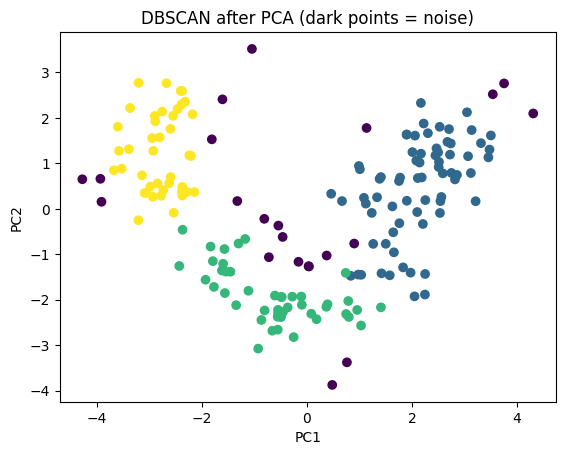

In [ ]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=db_after, cmap="viridis")
plt.title("DBSCAN after PCA (dark points = noise)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

DBSCAN works better after PCA (ARI 0.421 → 0.559), but K-Means is still better on this data.